In [1]:
!pip install pymatgen ase matplotlib numpy

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 829.7/829.7 kB 20.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 78.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 126.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 979.1/979.1 kB 38.7 MB/s  0:00:00
  Created wheel for bibtexparser: filename=bibtexparser-1.4.4-py3-none-any.whl size=43686 sha256=2f331527520773a8198409ffe52074f3ea5a114a3a54aab6cab37a7d8eb28f6a
  Stored in directory: /root/.cache/pip/wheels/43/ca/d8/0d315657fcf8ff8694a2f6701589bd1eaa602a85b7a7810063
Successfully built bibtexparser
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [pymatgen]
ERROR: pip's dependency resolver do

In [2]:
from importlib.metadata import version
import numpy, matplotlib
print("pymatgen", version("pymatgen"))
print("ase", version("ase"))
print("Everything is installed")

pymatgen 2026.10.24
ase 3.29.0
Everything is installed


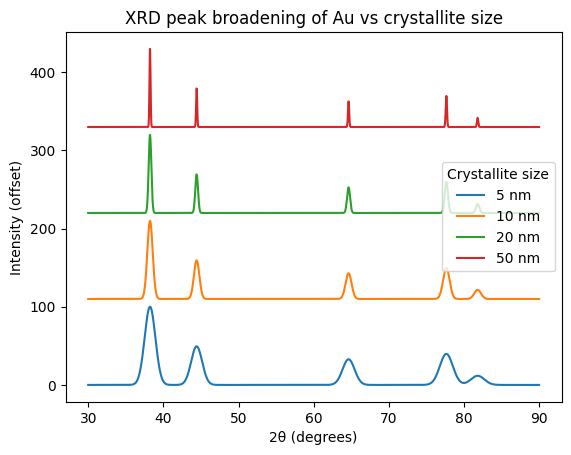

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from pymatgen.core import Structure, Lattice
from pymatgen.analysis.diffraction.xrd import XRDCalculator

# Gold (fcc) as a simple test material
au = Structure.from_spacegroup("Fm-3m", Lattice.cubic(4.078), ["Au"], [[0, 0, 0]])

xrd = XRDCalculator(wavelength="CuKa")
pattern = xrd.get_pattern(au, two_theta_range=(30, 90))

K = 0.9              # Scherrer shape factor
lam = 0.154184       # Cu K-alpha wavelength in nm
x = np.linspace(30, 90, 3000)

def broadened(size_nm):
    y = np.zeros_like(x)
    for x0, i0 in zip(pattern.x, pattern.y):
        theta = np.radians(x0 / 2)
        fwhm = np.degrees(K * lam / (size_nm * np.cos(theta)))  # peak width in 2-theta (degrees)
        sigma = fwhm / 2.355
        y += i0 * np.exp(-((x - x0) ** 2) / (2 * sigma ** 2))
    return y

for i, d in enumerate([5, 10, 20, 50]):
    plt.plot(x, broadened(d) + i * 110, label=f"{d} nm")

plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (offset)")
plt.legend(title="Crystallite size", loc="center right")
plt.title("XRD peak broadening of Au vs crystallite size")
plt.show()